# 3. LSTM Modell (Deep Learning Algorithmus)

In diesem Notebook trainieren wir ein Bidirectional LSTM Modell für Sentiment-Analyse.


In [1]:
# Import der benötigten Bibliotheken
import os
os.environ["PYTHONIOENCODING"] = "utf-8"  
import random
import numpy as np
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')  

# Basis-Verzeichnis des Projekts ermitteln
current_dir = Path().resolve()
if current_dir.name == 'src':
    BASE_DIR = current_dir.parent
else:
    BASE_DIR = current_dir

sys.path.insert(0, str(BASE_DIR / "src"))

from utils_imdb import read_imdb_split, basic_clean, SEED

# TensorFlow und Keras importieren
import tensorflow as tf
from keras import Sequential
from keras.layers import TextVectorization, Embedding, LSTM, Dense, Dropout, Bidirectional
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Reproduzierbarkeit sicherstellen: Alle Zufallszahlen mit gleichem Seed
# Dies ist wichtig, damit Experimente wiederholbar sind
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")



## 3.1 Daten laden und vorbereiten


In [2]:
# Pfade definieren
DATA_ROOT = BASE_DIR / "data" / "aclImdb"
OUTPUT_DIR = BASE_DIR / "outputs"
MODELS_DIR = OUTPUT_DIR / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  
MODELS_DIR.mkdir(parents=True, exist_ok=True)  

# Hyperparameter für das LSTM-Modell
MAX_DOCS_PER_CLASS = None  
MAX_VOCAB = 40_000  
MAX_LEN = 300  
EMBED_DIM = 100  
BATCH_SIZE = 64  
EPOCHS = 6  

print("Lade Daten...")
# Trainings- und Testdaten laden
train = read_imdb_split(DATA_ROOT / "train", max_docs_per_class=MAX_DOCS_PER_CLASS)
test = read_imdb_split(DATA_ROOT / "test", max_docs_per_class=MAX_DOCS_PER_CLASS)

# Prüfe ob Daten geladen wurden
if len(train) == 0:
    raise ValueError("FEHLER: Keine Trainingsdaten geladen! ")
if len(test) == 0:
    raise ValueError("FEHLER: Keine Testdaten geladen! ")

# Datenvorverarbeitung:
# - Texte bereinigen und in Liste umwandeln 
Xtr = train["text"].apply(basic_clean).tolist()
Xte = test["text"].apply(basic_clean).tolist()
ytr = train["label"].to_numpy(dtype="int64")
yte = test["label"].to_numpy(dtype="int64")

print(f"Trainingsdaten: {len(Xtr)} Reviews")
print(f"Testdaten: {len(Xte)} Reviews")


Lade Daten...


Reading neg: 100%|████████████████████████| 12500/12500 [05:30<00:00, 37.83it/s]


Trainingsdaten: 25000 Reviews
Testdaten: 25000 Reviews


## 3.2 Text Vectorization


In [3]:
# Text-Vektorisierer erstellen
# Dieser konvertiert Text in Sequenzen von Int-IDs
vectorizer = TextVectorization(
    max_tokens=MAX_VOCAB,  
    output_mode="int",  
    output_sequence_length=MAX_LEN  
)

print("Passe Vektorisierer an Trainingsdaten an...")
# Vektorisierer auf Trainingsdaten anpassen 
ds_text = tf.data.Dataset.from_tensor_slices(Xtr).batch(256)
vectorizer.adapt(ds_text)  # Vokabular aus Trainingsdaten lernen
print(f"Vokabular-Größe: {vectorizer.vocabulary_size()}")


Passe Vektorisierer an Trainingsdaten an...
Vokabular-Größe: 40000


## 3.3 Modell definieren


In [4]:
# Modell-Architektur aufbauen
model = Sequential([
    vectorizer,  # Text-Vektorisierung: Text -> Integer-Sequenzen
    Embedding(input_dim=MAX_VOCAB, output_dim=EMBED_DIM, input_length=MAX_LEN),
    # Embedding-Layer  (Wort-Embedding)
    Bidirectional(LSTM(128)),  # Bidirektionales LSTM
    # LSTM erfasst Sequenzinformationen (Wortreihenfolge, Kontext)
    Dropout(0.4),  
    Dense(64, activation="relu"), 
    Dropout(0.3), 
    Dense(1, activation="sigmoid"),     
])

# Modell kompilieren:  Loss-Funktion und Metriken definieren
model.compile(optimizer="adam",  # Adam Optimizer (adaptive Lernrate)
              loss="binary_crossentropy",  # Binäre Kreuzentropie für binäre Klassifikation
              metrics=["accuracy"])  
model.summary()  


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ ?                      │   0 (unbuilt) │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 3.4 Training


In [5]:
es = EarlyStopping(
    monitor="val_accuracy",  
    patience=2, 
    mode="max",  
    restore_best_weights=True  
)

print("Trainiere Modell...")
# Modell trainieren
history = model.fit(
    x=np.array(Xtr, dtype=object),  # Trainingsdaten 
    y=ytr,  # Trainings-Labels
    validation_split=0.15,  # 15% der Trainingsdaten als Validierungsset verwenden
    epochs=EPOCHS,  
    batch_size=BATCH_SIZE,  
    callbacks=[es], 
    verbose=1  
)


Trainiere Modell...
Epoch 1/6
333/333 ━━━━━━━━━━━━━━━━━━━━ 648s 2s/step - accuracy: 0.7354 - loss: 0.5264 - val_accuracy: 0.8088 - val_loss: 0.4359
Epoch 2/6
333/333 ━━━━━━━━━━━━━━━━━━━━ 550s 2s/step - accuracy: 0.8642 - loss: 0.3313 - val_accuracy: 0.7947 - val_loss: 0.6474
Epoch 3/6
333/333 ━━━━━━━━━━━━━━━━━━━━ 939s 3s/step - accuracy: 0.8835 - loss: 0.3036 - val_accuracy: 0.8248 - val_loss: 0.4720
Epoch 4/6
333/333 ━━━━━━━━━━━━━━━━━━━━ 810s 2s/step - accuracy: 0.9433 - loss: 0.1656 - val_accuracy: 0.8544 - val_loss: 0.4171
Epoch 5/6
333/333 ━━━━━━━━━━━━━━━━━━━━ 838s 3s/step - accuracy: 0.9638 - loss: 0.1135 - val_accuracy: 0.8445 - val_loss: 0.4640
Epoch 6/6
333/333 ━━━━━━━━━━━━━━━━━━━━ 753s 2s/step - accuracy: 0.9638 - loss: 0.1113 - val_accuracy: 0.8456 - val_loss: 0.5204


## 3.5 Training History Visualisierung


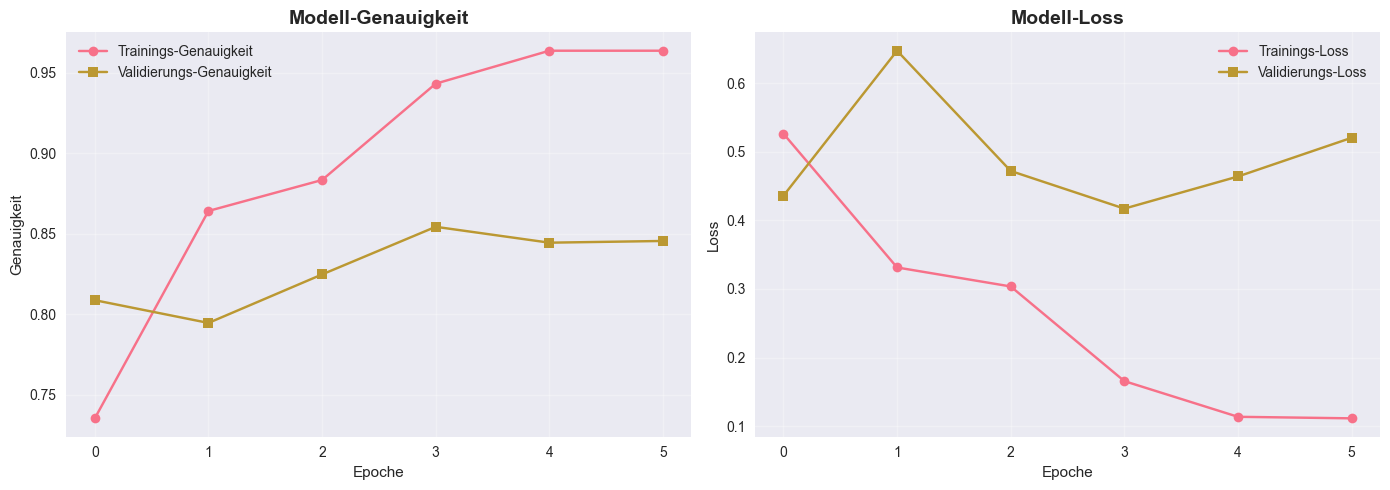

In [6]:
# Training-Verlauf visualisieren
# Zeigt, wie sich Genauigkeit und Loss während des Trainings entwickeln
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Genauigkeit über Epochen
axes[0].plot(history.history['accuracy'], label='Trainings-Genauigkeit', marker='o')
axes[0].plot(history.history['val_accuracy'], label='Validierungs-Genauigkeit', marker='s')
axes[0].set_title('Modell-Genauigkeit', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoche')
axes[0].set_ylabel('Genauigkeit')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss über Epochen
axes[1].plot(history.history['loss'], label='Trainings-Loss', marker='o')
axes[1].plot(history.history['val_loss'], label='Validierungs-Loss', marker='s')
axes[1].set_title('Modell-Loss', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoche')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_history_lstm.png", dpi=300, bbox_inches='tight')
plt.show()


## 3.6 Evaluation


In [7]:
# Vorhersagen auf Testdaten machen
print("Erstelle Vorhersagen...")
# Modell gibt Wahrscheinlichkeiten aus (zwischen 0 und 1)
proba = model.predict(np.array(Xte, dtype=object), batch_size=BATCH_SIZE).ravel()
# Konvertiere Wahrscheinlichkeiten zu binären Vorhersagen (>= 0.5 = Positiv)
pred = (proba >= 0.5).astype(int)

# Metriken berechnen und ausgeben
accuracy = accuracy_score(yte, pred)
print(f"\nTest-Genauigkeit (Accuracy): {accuracy:.4f}")
print("\nKlassifikationsbericht (Precision, Recall, F1-Score):")
print(classification_report(yte, pred, digits=4))
print("\nKonfusionsmatrix:")
# Konfusionsmatrix zeigt: True Negatives, False Positives, False Negatives, True Positives
cm = confusion_matrix(yte, pred)
print(cm)


Erstelle Vorhersagen...
391/391 ━━━━━━━━━━━━━━━━━━━━ 235s 581ms/step

Test-Genauigkeit (Accuracy): 0.8270

Klassifikationsbericht (Precision, Recall, F1-Score):
              precision    recall  f1-score   support

           0     0.8550    0.7874    0.8198     12500
           1     0.8030    0.8665    0.8335     12500

    accuracy                         0.8270     25000
   macro avg     0.8290    0.8270    0.8267     25000
weighted avg     0.8290    0.8270    0.8267     25000


Konfusionsmatrix:
[[ 9843  2657]
 [ 1669 10831]]


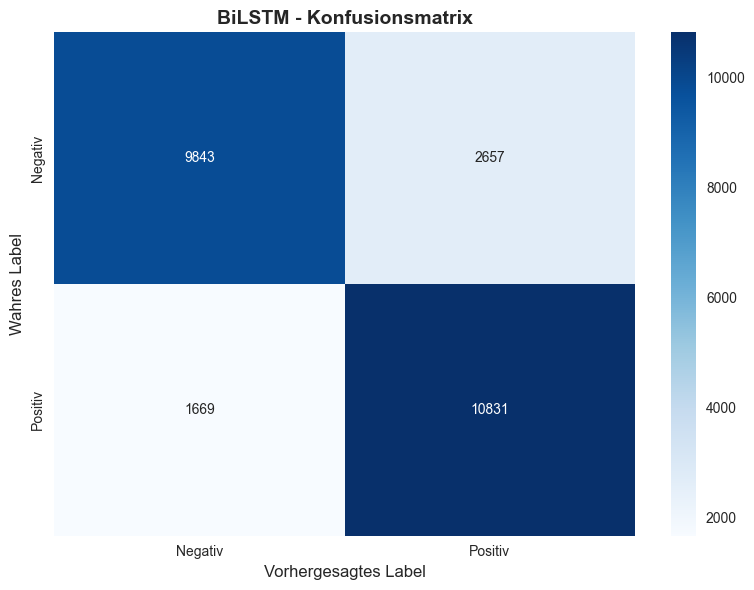

In [8]:
# Konfusionsmatrix visualisieren
# Die Heatmap zeigt, wie viele Reviews korrekt/inkorrekt klassifiziert wurden
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Negativ', 'Positiv'],
            yticklabels=['Negativ', 'Positiv'])
ax.set_title('BiLSTM - Konfusionsmatrix', fontsize=14, fontweight='bold')
ax.set_ylabel('Wahres Label', fontsize=12)
ax.set_xlabel('Vorhergesagtes Label', fontsize=12)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix_lstm.png", dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# Modell speichern für spätere Verwendung
SAVE_DIR = MODELS_DIR / "lstm_imdb_savedmodel"
model.export(str(SAVE_DIR))
print(f"Modell gespeichert: {SAVE_DIR}")

# Vorhersagen speichern für spätere Analyse und Vergleich
PRED_PATH = OUTPUT_DIR / "preds_lstm.csv"
pd.DataFrame({
    "text": Xte,      # Original-Text
    "y_true": yte,    # Wahre Labels
    "y_pred": pred,   # Vorhergesagte Labels (binär)
    "proba": proba    # Vorhergesagte Wahrscheinlichkeiten (kontinuierlich)
}).to_csv(PRED_PATH, index=False, encoding="utf-8")
print(f"Vorhersagen gespeichert: {PRED_PATH}")
